In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

In [2]:
import urllib.request, os

if not os.path.exists('mnist.npz'):
    urllib.request.urlretrieve(
        'https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz',
        'mnist.npz')

d = np.load('mnist.npz')

x_train = d['x_train'].reshape(-1, 784) / 255.0
y_train = d['y_train']
x_test  = d['x_test'].reshape(-1, 784)  / 255.0
y_test  = d['y_test']

def one_hot(y):
    oh = np.zeros((y.shape[0], 10))
    oh[np.arange(y.shape[0]), y] = 1
    return oh

y_train_oh = one_hot(y_train)
y_test_oh  = one_hot(y_test)

print(x_train.shape, x_test.shape)

(60000, 784) (10000, 784)


In [4]:
W1 = np.random.uniform(-0.5, 0.5, (784, 128))
b1 = np.zeros((1, 128))
W2 = np.random.uniform(-0.5, 0.5, (128, 64))
b2 = np.zeros((1, 64))
W3 = np.random.uniform(-0.5, 0.5, (64, 10))
b3 = np.zeros((1, 10))

In [5]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def sigmoid_deriv(a):
    return a * (1 - a)

In [6]:
def forward(X, W1, b1, W2, b2, W3, b3):
    a1 = sigmoid(X  @ W1 + b1)
    a2 = sigmoid(a1 @ W2 + b2)
    a3 = sigmoid(a2 @ W3 + b3)
    return a1, a2, a3

In [7]:
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

In [8]:
def backward(X, y, a1, a2, a3, W2, W3):
    m  = X.shape[0]
    d3 = -2 * (y - a3) * sigmoid_deriv(a3)
    dW3 = (a2.T @ d3) / m
    db3 = np.mean(d3, axis=0, keepdims=True)
    d2  = (d3 @ W3.T) * sigmoid_deriv(a2)
    dW2 = (a1.T @ d2) / m
    db2 = np.mean(d2, axis=0, keepdims=True)
    d1  = (d2 @ W2.T) * sigmoid_deriv(a1)
    dW1 = (X.T  @ d1) / m
    db1 = np.mean(d1, axis=0, keepdims=True)
    return dW1, db1, dW2, db2, dW3, db3

In [9]:
lr         = 0.1
epochs     = 20
batch_size = 32
losses     = []

for epoch in range(epochs):
    idx = np.random.permutation(x_train.shape[0])
    Xs  = x_train[idx]
    Ys  = y_train_oh[idx]

    for i in range(0, x_train.shape[0], batch_size):
        Xb = Xs[i:i+batch_size]
        Yb = Ys[i:i+batch_size]
        a1, a2, a3 = forward(Xb, W1, b1, W2, b2, W3, b3)
        dW1,db1,dW2,db2,dW3,db3 = backward(Xb, Yb, a1, a2, a3, W2, W3)
        W1-=lr*dW1; b1-=lr*db1
        W2-=lr*dW2; b2-=lr*db2
        W3-=lr*dW3; b3-=lr*db3

    _, _, a3_all = forward(x_train, W1, b1, W2, b2, W3, b3)
    loss = mse(y_train_oh, a3_all)
    losses.append(loss)
    print(f'Epoch {epoch+1}/{epochs}  Loss: {loss:.4f}')

Epoch 1/20  Loss: 0.0303
Epoch 2/20  Loss: 0.0209
Epoch 3/20  Loss: 0.0172
Epoch 4/20  Loss: 0.0152
Epoch 5/20  Loss: 0.0140
Epoch 6/20  Loss: 0.0127
Epoch 7/20  Loss: 0.0119
Epoch 8/20  Loss: 0.0111
Epoch 9/20  Loss: 0.0105
Epoch 10/20  Loss: 0.0100
Epoch 11/20  Loss: 0.0096
Epoch 12/20  Loss: 0.0092
Epoch 13/20  Loss: 0.0088
Epoch 14/20  Loss: 0.0084
Epoch 15/20  Loss: 0.0081
Epoch 16/20  Loss: 0.0079
Epoch 17/20  Loss: 0.0077
Epoch 18/20  Loss: 0.0074
Epoch 19/20  Loss: 0.0072
Epoch 20/20  Loss: 0.0069


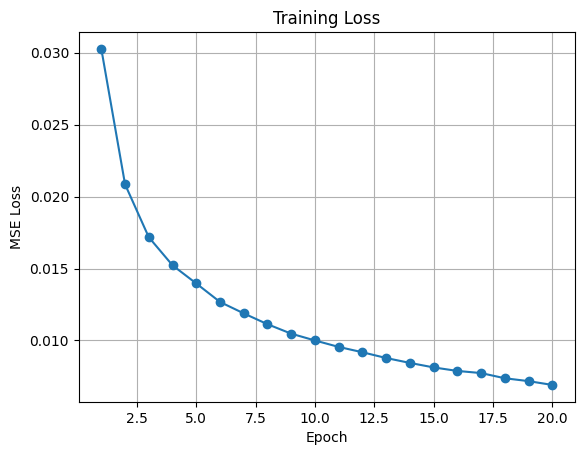

In [10]:
plt.plot(range(1, epochs+1), losses, marker='o')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training Loss')
plt.grid(True)
plt.savefig('loss_curve.png', dpi=150)
plt.show()

In [11]:
_, _, a3_test = forward(x_test, W1, b1, W2, b2, W3, b3)
preds    = np.argmax(a3_test, axis=1)
accuracy = np.mean(preds == y_test) * 100
print(f'Test Accuracy: {accuracy:.2f}%')

Test Accuracy: 95.63%


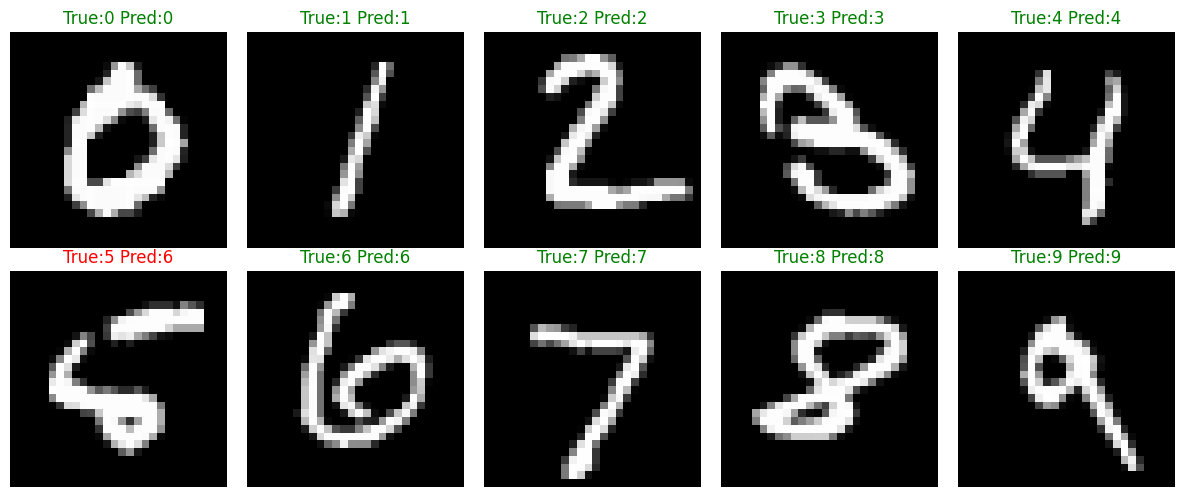

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes = axes.flatten()

for digit in range(10):
    idx = np.where(y_test == digit)[0][0]
    axes[digit].imshow(x_test[idx].reshape(28, 28), cmap='gray')
    color = 'green' if preds[idx] == y_test[idx] else 'red'
    axes[digit].set_title(f'True:{y_test[idx]} Pred:{preds[idx]}', color=color)
    axes[digit].axis('off')

plt.tight_layout()
plt.savefig('predictions.png', dpi=150)
plt.show()